# 05 - FDNY monthly response times (validation benchmark)
**Input:** `data/raw/fdny_monthly_response_times.csv` (`j34j-vqvt`)
**Output:** `data/interim/fdny_monthly_clean.csv`

Used to sanity-check our simulator's baseline: replayed static-policy response times should be in the same range as
the published averages. Caveat: FDNY's "Medical Emergencies" figures cover all first responders, not only ambulances.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "README.md").exists())
sys.path.insert(0, str(ROOT / "src"))
RAW, INTERIM, PROCESSED = ROOT / "data/raw", ROOT / "data/interim", ROOT / "data/processed"
NB_DATA = ROOT / "notebooks/data"
INTERIM.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

In [2]:
m = pd.read_csv(RAW / "fdny_monthly_response_times.csv", dtype=str)
print(m.yearmonth.str.slice(0, 2).value_counts().head(3).to_dict(), "<- non-month labels like 'FY 2021' exist")
m = m[m.yearmonth.str.fullmatch(r"\d{4}/\d{2}")].copy()          # keep calendar months only
m["month"] = pd.to_datetime(m.yearmonth + "/01", format="%Y/%m/%d")
m["incidentcount"] = pd.to_numeric(m.incidentcount, errors="coerce")
mm = m.averageresponsetime.str.extract(r"(?P<m>\d+):(?P<s>\d+)").astype(float)
m["avg_response_s"] = mm.m * 60 + mm.s
m = m.rename(columns={"incidentclassification": "classification", "incidentborough": "borough"})
m["borough"] = m.borough.str.upper()
m = m[["month", "classification", "borough", "incidentcount", "avg_response_s"]].dropna(subset=["avg_response_s"])
print(m.classification.unique())
m.to_csv(INTERIM / "fdny_monthly_clean.csv", index=False); m.tail()

{'20': 6048, 'FY': 504} <- non-month labels like 'FY 2021' exist
['All Fire/Emergency Incidents' 'False Alarm' 'Medical Emergencies'
 'Medical False Alarm' 'NonMedical Emergencies' 'NonStructural Fires'
 'Structural Fires']


,month,classification,borough,incidentcount,avg_response_s
6043,2021-06-01,Structural Fires,BROOKLYN,546,235.0
6044,2021-06-01,Structural Fires,CITYWIDE,1843,264.0
6045,2021-06-01,Structural Fires,MANHATTAN,374,268.0
6046,2021-06-01,Structural Fires,QUEENS,408,286.0
6047,2021-06-01,Structural Fires,STATEN ISLAND,102,287.0


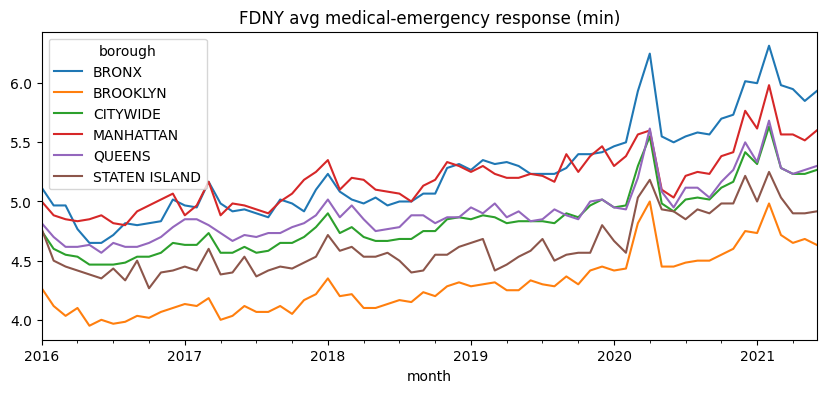

In [3]:
med = m[(m.classification == "Medical Emergencies") & (m.month >= "2016-01-01")]
(med.pivot(index="month", columns="borough", values="avg_response_s") / 60).plot(figsize=(10, 4), title="FDNY avg medical-emergency response (min)")
plt.show()